<div class='bar_title'></div>

*Practical Data Science - Final Project (WS 2026/27)*

# Forecasting German Day-Ahead Electricity Prices
## Part 2: Price Forecasting Models

Group members: Rashad Zarbaliyev, [Member 2], [Member 3]<br>
Data: SMARD, Bundesnetzagentur (CC BY 4.0)

### Running this notebook in Google Colab
Run the next cell first. On your own computer it does nothing. In Colab it gets the project files and installs the missing package.
Because the GitHub repository is private, Colab may ask you to upload the project ZIP (`PDS_Submission_Electricity_Price_Forecasting.zip`).

In [ ]:
# Colab setup (skipped automatically when running locally)
import os, sys, subprocess
if 'google.colab' in sys.modules and not os.path.exists('../src/data_pipeline.py'):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'holidays'])
    repo = 'https://github.com/greenmario2099/pds-electricity-price-forecasting'
    env = dict(os.environ, GIT_TERMINAL_PROMPT='0')
    if not os.path.exists('/content/project'):
        cloned = subprocess.run(['git', 'clone', '-q', '--depth', '1', repo, '/content/project'], env=env).returncode == 0
        if not cloned:
            import glob, zipfile
            from google.colab import files
            print('Repository is private: please upload the project ZIP.')
            name = list(files.upload())[0]
            zipfile.ZipFile(name).extractall('/content/upload')
            pipeline = glob.glob('/content/upload/**/src/data_pipeline.py', recursive=True)[0]
            os.symlink(os.path.dirname(os.path.dirname(pipeline)), '/content/project')
    os.chdir('/content/project/notebooks')
    print('Ready:', os.getcwd())

# Content

* Setup: features and time-based split
* Evaluation metrics
* Baselines: seasonal naive and linear regression
* Advanced models: random forest and neural network (MLP)
* Monthly retraining: how much history should we use?
* Model selection on the validation year 2025
* Final evaluation on the test set 2026
* Error analysis
* Which features matter?
* Saving the predictions for the dashboard

In [1]:
import sys
sys.path.append('..')   # so that we can import our own pipeline from the src/ folder

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data_pipeline import load_data, build_features, FEATURES

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 4)
DATA_DIR = '../data/'

from src.data_pipeline import split_by_time, rolling_forecast

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

## Setup

We load the data and build all features with our pipeline (see notebook 01 and `src/data_pipeline.py`).

In [2]:
data = load_data(DATA_DIR)
features = build_features(data)
print(features.shape)
print(len(FEATURES), 'features:', FEATURES)

(70538, 29)
27 features: ['load_fc', 'residual_load_fc', 'wind_onshore_fc', 'wind_offshore_fc', 'solar_fc', 'renewable_share', 'residual_load_ramp', 'residual_load_rel_day', 'residual_load_day_max', 'residual_load_day_min', 'residual_load_change_24h', 'hour', 'weekday', 'month', 'day_of_year', 'weekend', 'holiday', 'lag24', 'lag48', 'lag168', 'same_hour_mean_7d', 'prev_day_mean', 'prev_day_min', 'prev_day_max', 'mean_7d', 'mean_30d', 'std_7d']


### Time-based split

Time series must **not** be split randomly, otherwise the model would learn from the future. We use three consecutive periods:

| Set | Period | Purpose |
| --- | --- | --- |
| Training | 2023-01 to 2024-12 | Fit the models (after the energy crisis) |
| Validation | 2025-01 to 2025-12 | Compare models and choose the final model |
| Test | 2026-01 to 2026-11 | Final evaluation, used only once at the end |

In [3]:
train, val, test = split_by_time(features)

train_X, train_y = train[FEATURES], train['price']
val_X, val_y = val[FEATURES], val['price']
test_X, test_y = test[FEATURES], test['price']

print('train:', train_X.shape, ' val:', val_X.shape, ' test:', test_X.shape)

train: (17544, 27)  val: (8760, 27)  test: (7704, 27)


## Evaluation Metrics

* **MAE** (main metric): average absolute error in EUR/MWh, easy to interpret and robust to single extreme hours.
* **RMSE**: penalizes large errors more, so it shows how well extreme hours are handled.
* **MAE on extreme hours**: error on hours with negative prices and on price spikes (top 5% of prices in the evaluated period).

We do not use MAPE: prices close to zero (or negative) make percentage errors meaningless.

In [4]:
def evaluate(y_true, y_pred):
    y_pred = pd.Series(np.asarray(y_pred), index=y_true.index)
    spike = y_true > y_true.quantile(0.95)
    negative = y_true < 0
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAE spikes (top 5%)': mean_absolute_error(y_true[spike], y_pred[spike]),
            'MAE negative hours': mean_absolute_error(y_true[negative], y_pred[negative])}

val_results = {}

## Baselines

### Baseline 1: Seasonal naive

*The price tomorrow at hour h equals the price today at hour h* (`lag24`), or one week ago (`lag168`). Any useful model must beat this.

In [5]:
val_results['Naive (same hour yesterday)'] = evaluate(val_y, val_X['lag24'])
val_results['Naive (same hour last week)'] = evaluate(val_y, val_X['lag168'])
pd.DataFrame(val_results).T.round(2)

,MAE,RMSE,MAE spikes (top 5%),MAE negative hours
Naive (same hour yesterday),25.97,40.45,69.87,27.08
Naive (same hour last week),32.83,49.33,75.09,42.70


### Baseline 2: Linear regression

A linear regression on all features. We standardize the features first, so that the coefficients are comparable:
each coefficient is the price change (EUR/MWh) for an increase of one standard deviation.

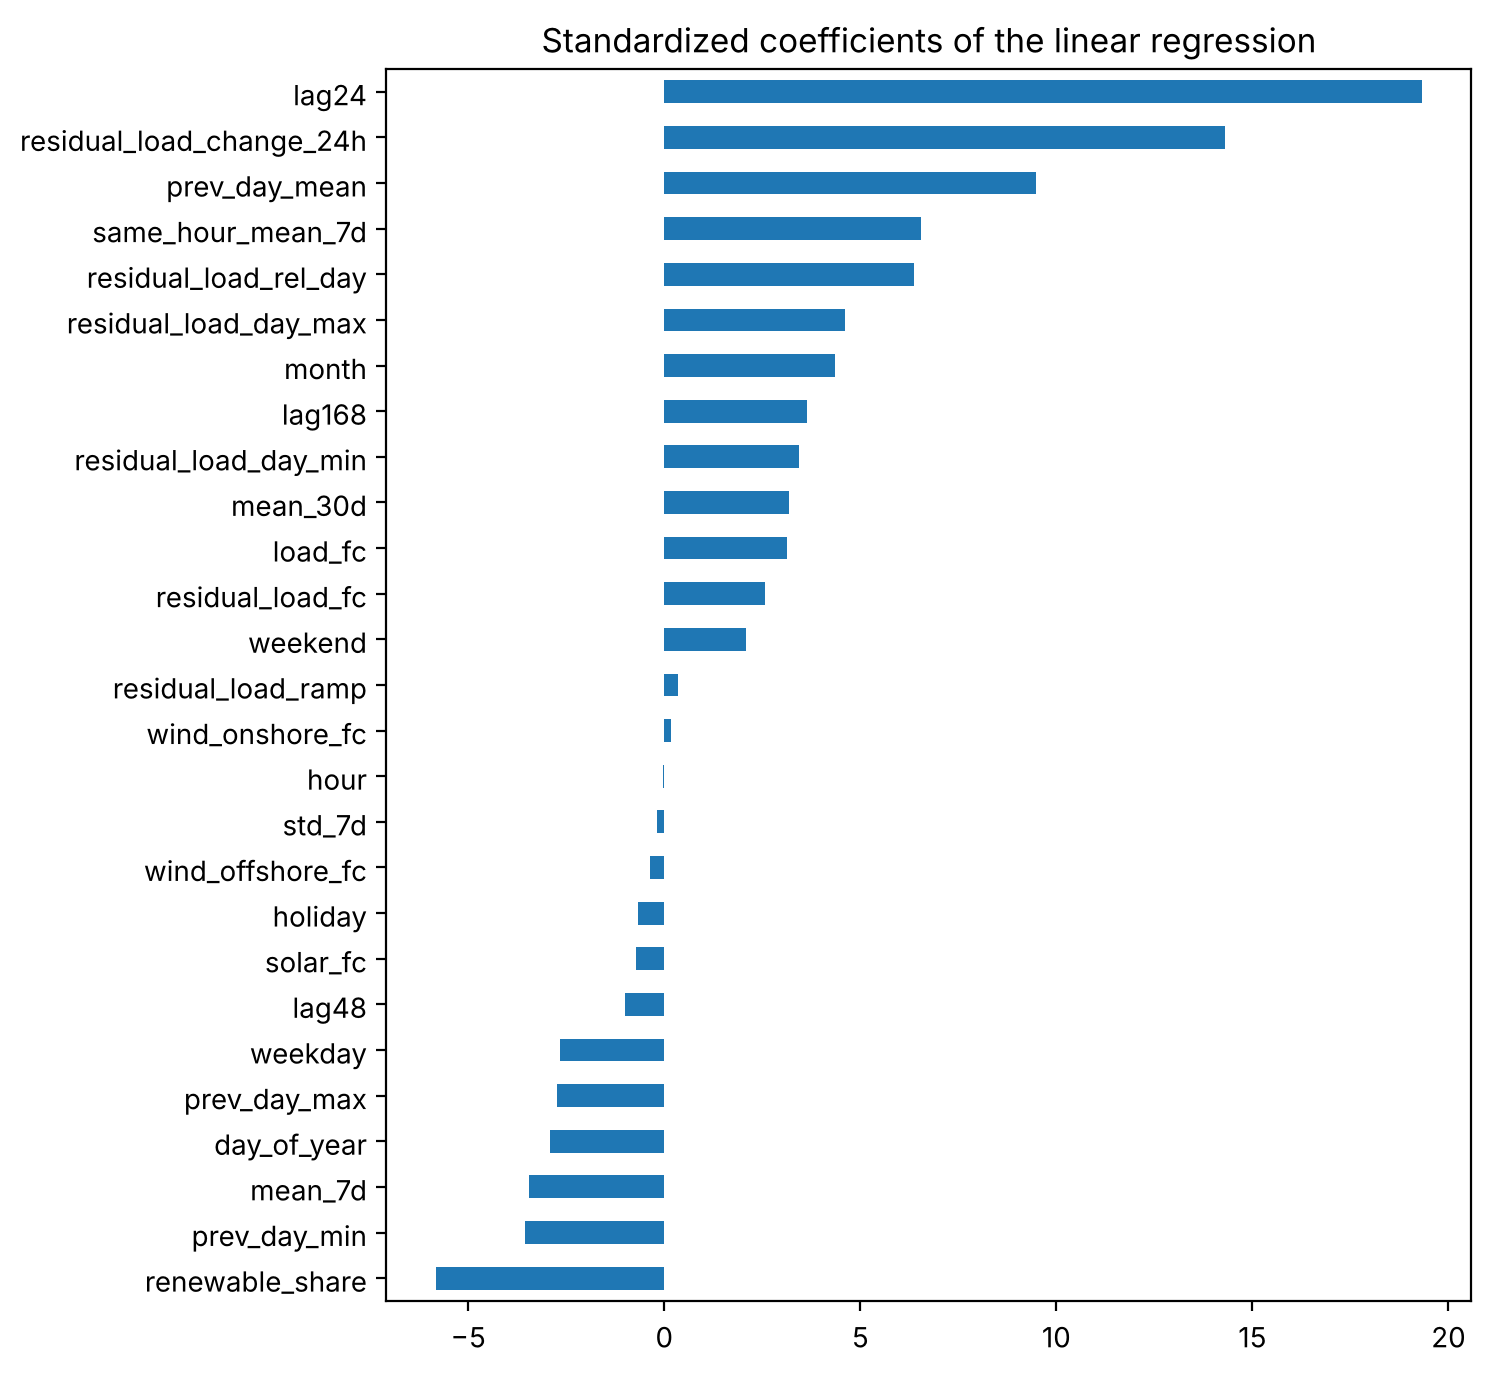

In [6]:
# Define
lin_model = make_pipeline(StandardScaler(), LinearRegression())
# Fit
lin_model.fit(train_X, train_y)
# Predict
val_results['Linear regression'] = evaluate(val_y, lin_model.predict(val_X))

coefs = pd.Series(lin_model[-1].coef_, index=FEATURES).sort_values()
coefs.plot(kind='barh', figsize=(7, 8), title='Standardized coefficients of the linear regression');

* The largest positive effects come from yesterday's price at the same hour (`lag24`), the change of the residual load compared to yesterday
  (`residual_load_change_24h`) and the previous day's average price.
* A high renewable share lowers the price.
* The individual wind and solar coefficients are close to zero: their information is already contained in the residual load and the renewable share
  (the features are highly correlated, so single coefficients must be interpreted with care).

The linear model is already a strong baseline: prices are persistent, and the residual-load change tells the model how tomorrow differs from today.

## Advanced Models

### Random forest

A random forest averages many decision trees, each trained on a bootstrap sample of the data and a random subset of features.
Trees can learn non-linear effects such as the merit-order curve, which a linear model cannot.

In [7]:
def make_rf():
    return RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=1)

rf_model = make_rf()
rf_model.fit(train_X, train_y)
val_results['Random forest'] = evaluate(val_y, rf_model.predict(val_X))

### Neural network (multi-layer perceptron)

As in lecture 05, we train a multi-layer perceptron. Neural networks need standardized inputs.
`early_stopping=True` keeps 10% of the training data aside and stops training when the error on this part stops improving.

In [8]:
def make_mlp():
    return make_pipeline(StandardScaler(),
                         MLPRegressor(hidden_layer_sizes=(128, 64), early_stopping=True, max_iter=300, random_state=1))

mlp_model = make_mlp()
mlp_model.fit(train_X, train_y)
val_results['Neural network (MLP)'] = evaluate(val_y, mlp_model.predict(val_X))

pd.DataFrame(val_results).T.round(2).sort_values('MAE')

,MAE,RMSE,MAE spikes (top 5%),MAE negative hours
Random forest,13.53,22.17,43.00,15.41
Linear regression,14.55,22.13,40.33,16.11
Neural network (MLP),15.09,24.29,45.94,18.37
Naive (same hour yesterday),25.97,40.45,69.87,27.08
Naive (same hour last week),32.83,49.33,75.09,42.70


All three learned models roughly halve the error of the naive forecast. With one fixed training period, the random forest is best.

## Monthly Retraining: How Much History Should We Use?

In practice, a forecasting model is retrained regularly with the newest data. We simulate this with a simple loop
(function `rolling_forecast` in our pipeline): **for each month, train on the previous N days and predict that month.**

How long should N be? A long window has more data, but includes old market situations such as the 2022 energy crisis.
We test this on the validation year 2025 with the random forest (this cell takes about 5 minutes).

In [9]:
val_months = pd.period_range('2025-01', '2025-12', freq='M')

window_results = {}
for days in [365, 730, 1095]:
    pred = rolling_forecast(features, make_rf, val_months, FEATURES, window_days=days)
    window_results[f'{days // 365} year(s)'] = mean_absolute_error(val_y, pred)

pd.Series(window_results, name='Validation MAE 2025 (random forest, monthly retraining)').round(2)

1 year(s)    14.66
2 year(s)    12.97
3 year(s)    13.27
Name: Validation MAE 2025 (random forest, monthly retraining), dtype: float64

A two-year window gives the lowest error (12.97 vs. 14.66 for one year and 13.27 for three years). One year is too little data;
longer windows include the energy crisis, whose price dynamics no longer represent today's market. **We use a two-year window from now on.**
Monthly retraining also helps by itself: the random forest improves from 13.53 (trained once on 2023-2024) to 12.97.

## Model Selection on the Validation Year 2025

We now compare all models with monthly retraining (two-year window) on the validation year.
We also try the **simple average** of the three learned models: different models make different errors, so averaging often helps
(Nowotarski et al., 2014). No weights are fitted - every model counts the same.

In [10]:
models = {
    'Linear regression': lambda: make_pipeline(StandardScaler(), LinearRegression()),
    'Random forest': make_rf,
    'Neural network (MLP)': make_mlp,
}

def rolling_all_models(months, y_true, naive):
    preds = pd.DataFrame({'Naive (same hour yesterday)': naive}, index=y_true.index)
    for name, make_model in models.items():
        preds[name] = rolling_forecast(features, make_model, months, FEATURES, window_days=730)
    preds['Average of the three models'] = preds[list(models)].mean(axis=1)
    return preds

val_preds = rolling_all_models(val_months, val_y, val_X['lag24'])
val_table = pd.DataFrame({m: evaluate(val_y, val_preds[m]) for m in val_preds}).T.sort_values('MAE')
val_table.round(2)

,MAE,RMSE,MAE spikes (top 5%),MAE negative hours
Average of the three models,12.43,20.13,39.84,13.44
Random forest,12.97,21.53,42.80,13.28
Neural network (MLP),14.36,23.38,44.56,16.74
Linear regression,14.55,22.09,40.12,16.00
Naive (same hour yesterday),25.97,40.45,69.87,27.08


In [11]:
final_model_name = val_table['MAE'].idxmin()
print('Model with the lowest validation MAE:', final_model_name)

Model with the lowest validation MAE: Average of the three models


The average of linear regression, random forest and MLP has the lowest validation error, so it is our **final model**.
This choice is made **before** looking at the test set. We report all models on the test set for transparency,
but the final model is the one selected here.

## Final Evaluation on the Test Set (2026)

Same setup: every month of 2026 is predicted by models trained only on the two years before that month.

In [12]:
test_months = pd.period_range('2026-01', '2026-11', freq='M')
test_preds = rolling_all_models(test_months, test_y, test_X['lag24'])

test_table = pd.DataFrame({m: evaluate(test_y, test_preds[m]) for m in test_preds}).T.sort_values('MAE')
naive_mae = test_table.loc['Naive (same hour yesterday)', 'MAE']
test_table['MAE improvement vs naive (%)'] = (1 - test_table['MAE'] / naive_mae) * 100
test_table.round(2)

,MAE,RMSE,MAE spikes (top 5%),MAE negative hours,MAE improvement vs naive (%)
Average of the three models,18.18,27.76,50.13,18.12,45.34
Linear regression,20.39,31.59,59.57,20.75,38.69
Random forest,21.00,31.76,63.56,19.66,36.86
Neural network (MLP),23.37,33.20,47.75,22.00,29.72
Naive (same hour yesterday),33.25,51.57,68.97,41.43,0.00


**Results on the test set**

* The pre-selected average of the three models has the lowest test MAE: **18.2 EUR/MWh, 45% better than the naive forecast** (33.3).
  It also has the lowest RMSE and the lowest error in negative-price hours.
* The ranking of the single models changes compared to 2025: on the test set, the linear regression beats the random forest.
  2026 has a much higher price level than the training years. Tree models cannot predict values outside the range seen in training,
  while a linear model can extrapolate. Averaging the models reduces this risk, which is why the average is the most robust choice.
* The MLP alone has the lowest error on price spikes: the three models make different errors, so their average is better than each of them.
* All errors are larger in 2026 than in 2025 because prices are higher and more volatile (standard deviation 76 vs. 52 EUR/MWh).

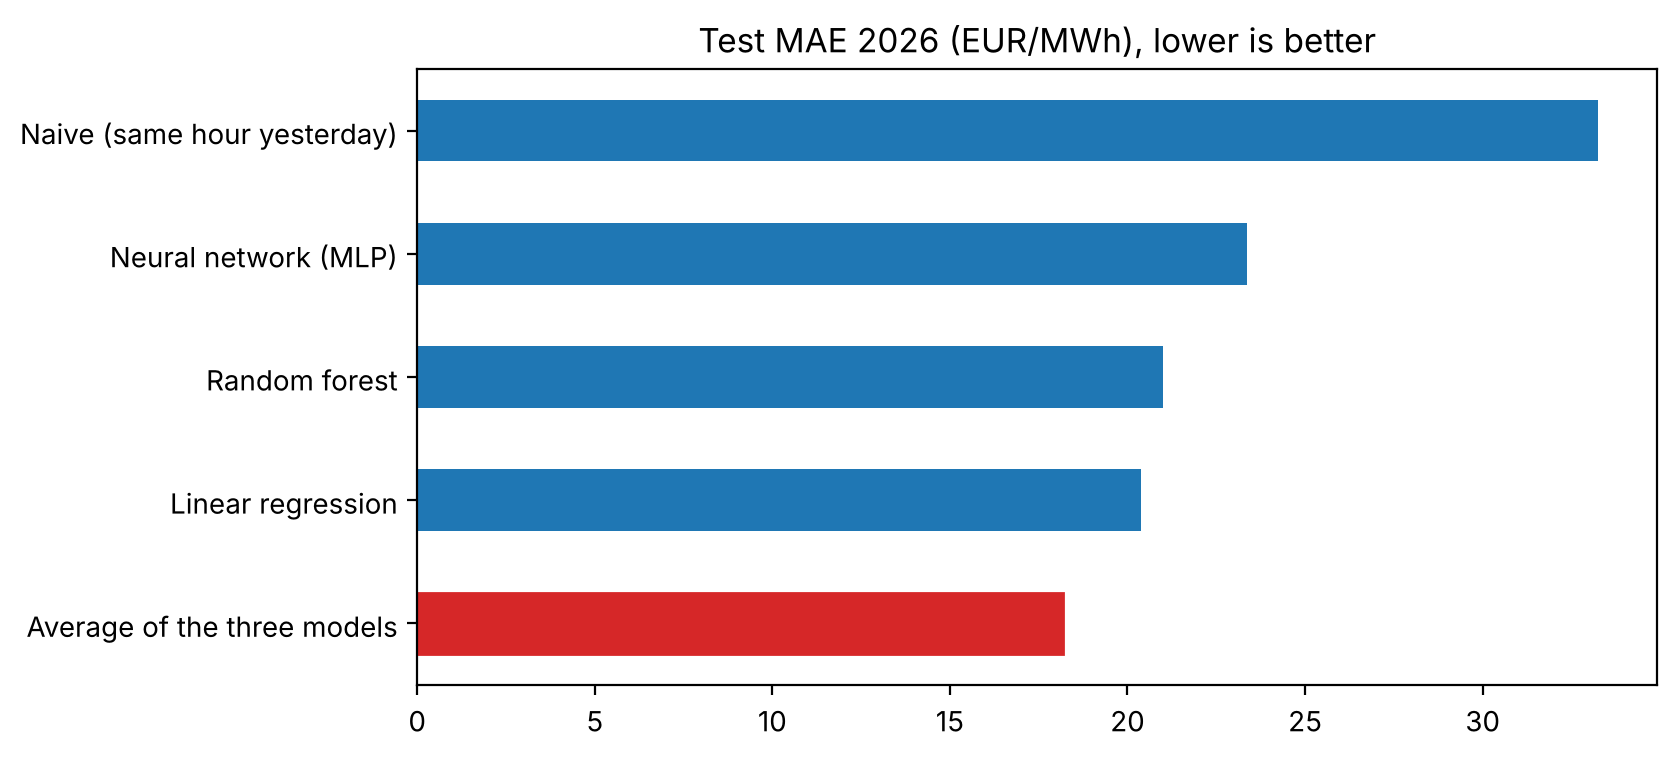

In [13]:
ax = test_table['MAE'].sort_values().plot(kind='barh', figsize=(8, 4), title='Test MAE 2026 (EUR/MWh), lower is better')
ax.get_children()[list(test_table['MAE'].sort_values().index).index(final_model_name)].set_color('tab:red')

### Is the final model better on most days, or only on a few?

A lower average error could come from a few lucky days. We therefore compute the error of each model **per day** and count
on how many of the test days the final model was more accurate than each other model.

In [14]:
daily_mae = (test_preds.sub(test_y, axis=0)).abs().groupby(test_y.index.date).mean()

wins = {other: (daily_mae[final_model_name] < daily_mae[other]).mean() * 100
        for other in daily_mae.columns if other != final_model_name}
pd.Series(wins, name=f'% of days on which the final model is better ({len(daily_mae)} days)').round(1)

Naive (same hour yesterday)    78.8
Linear regression              64.2
Random forest                  61.4
Neural network (MLP)           72.6
Name: % of days on which the final model is better (321 days), dtype: float64

The final model is more accurate than the naive forecast on 79% of the 321 test days, and better than each single model on
61-73% of the days. So the improvement is not driven by a few days; it holds on most days of the year.

## Error Analysis

### Forecasts vs. actual prices

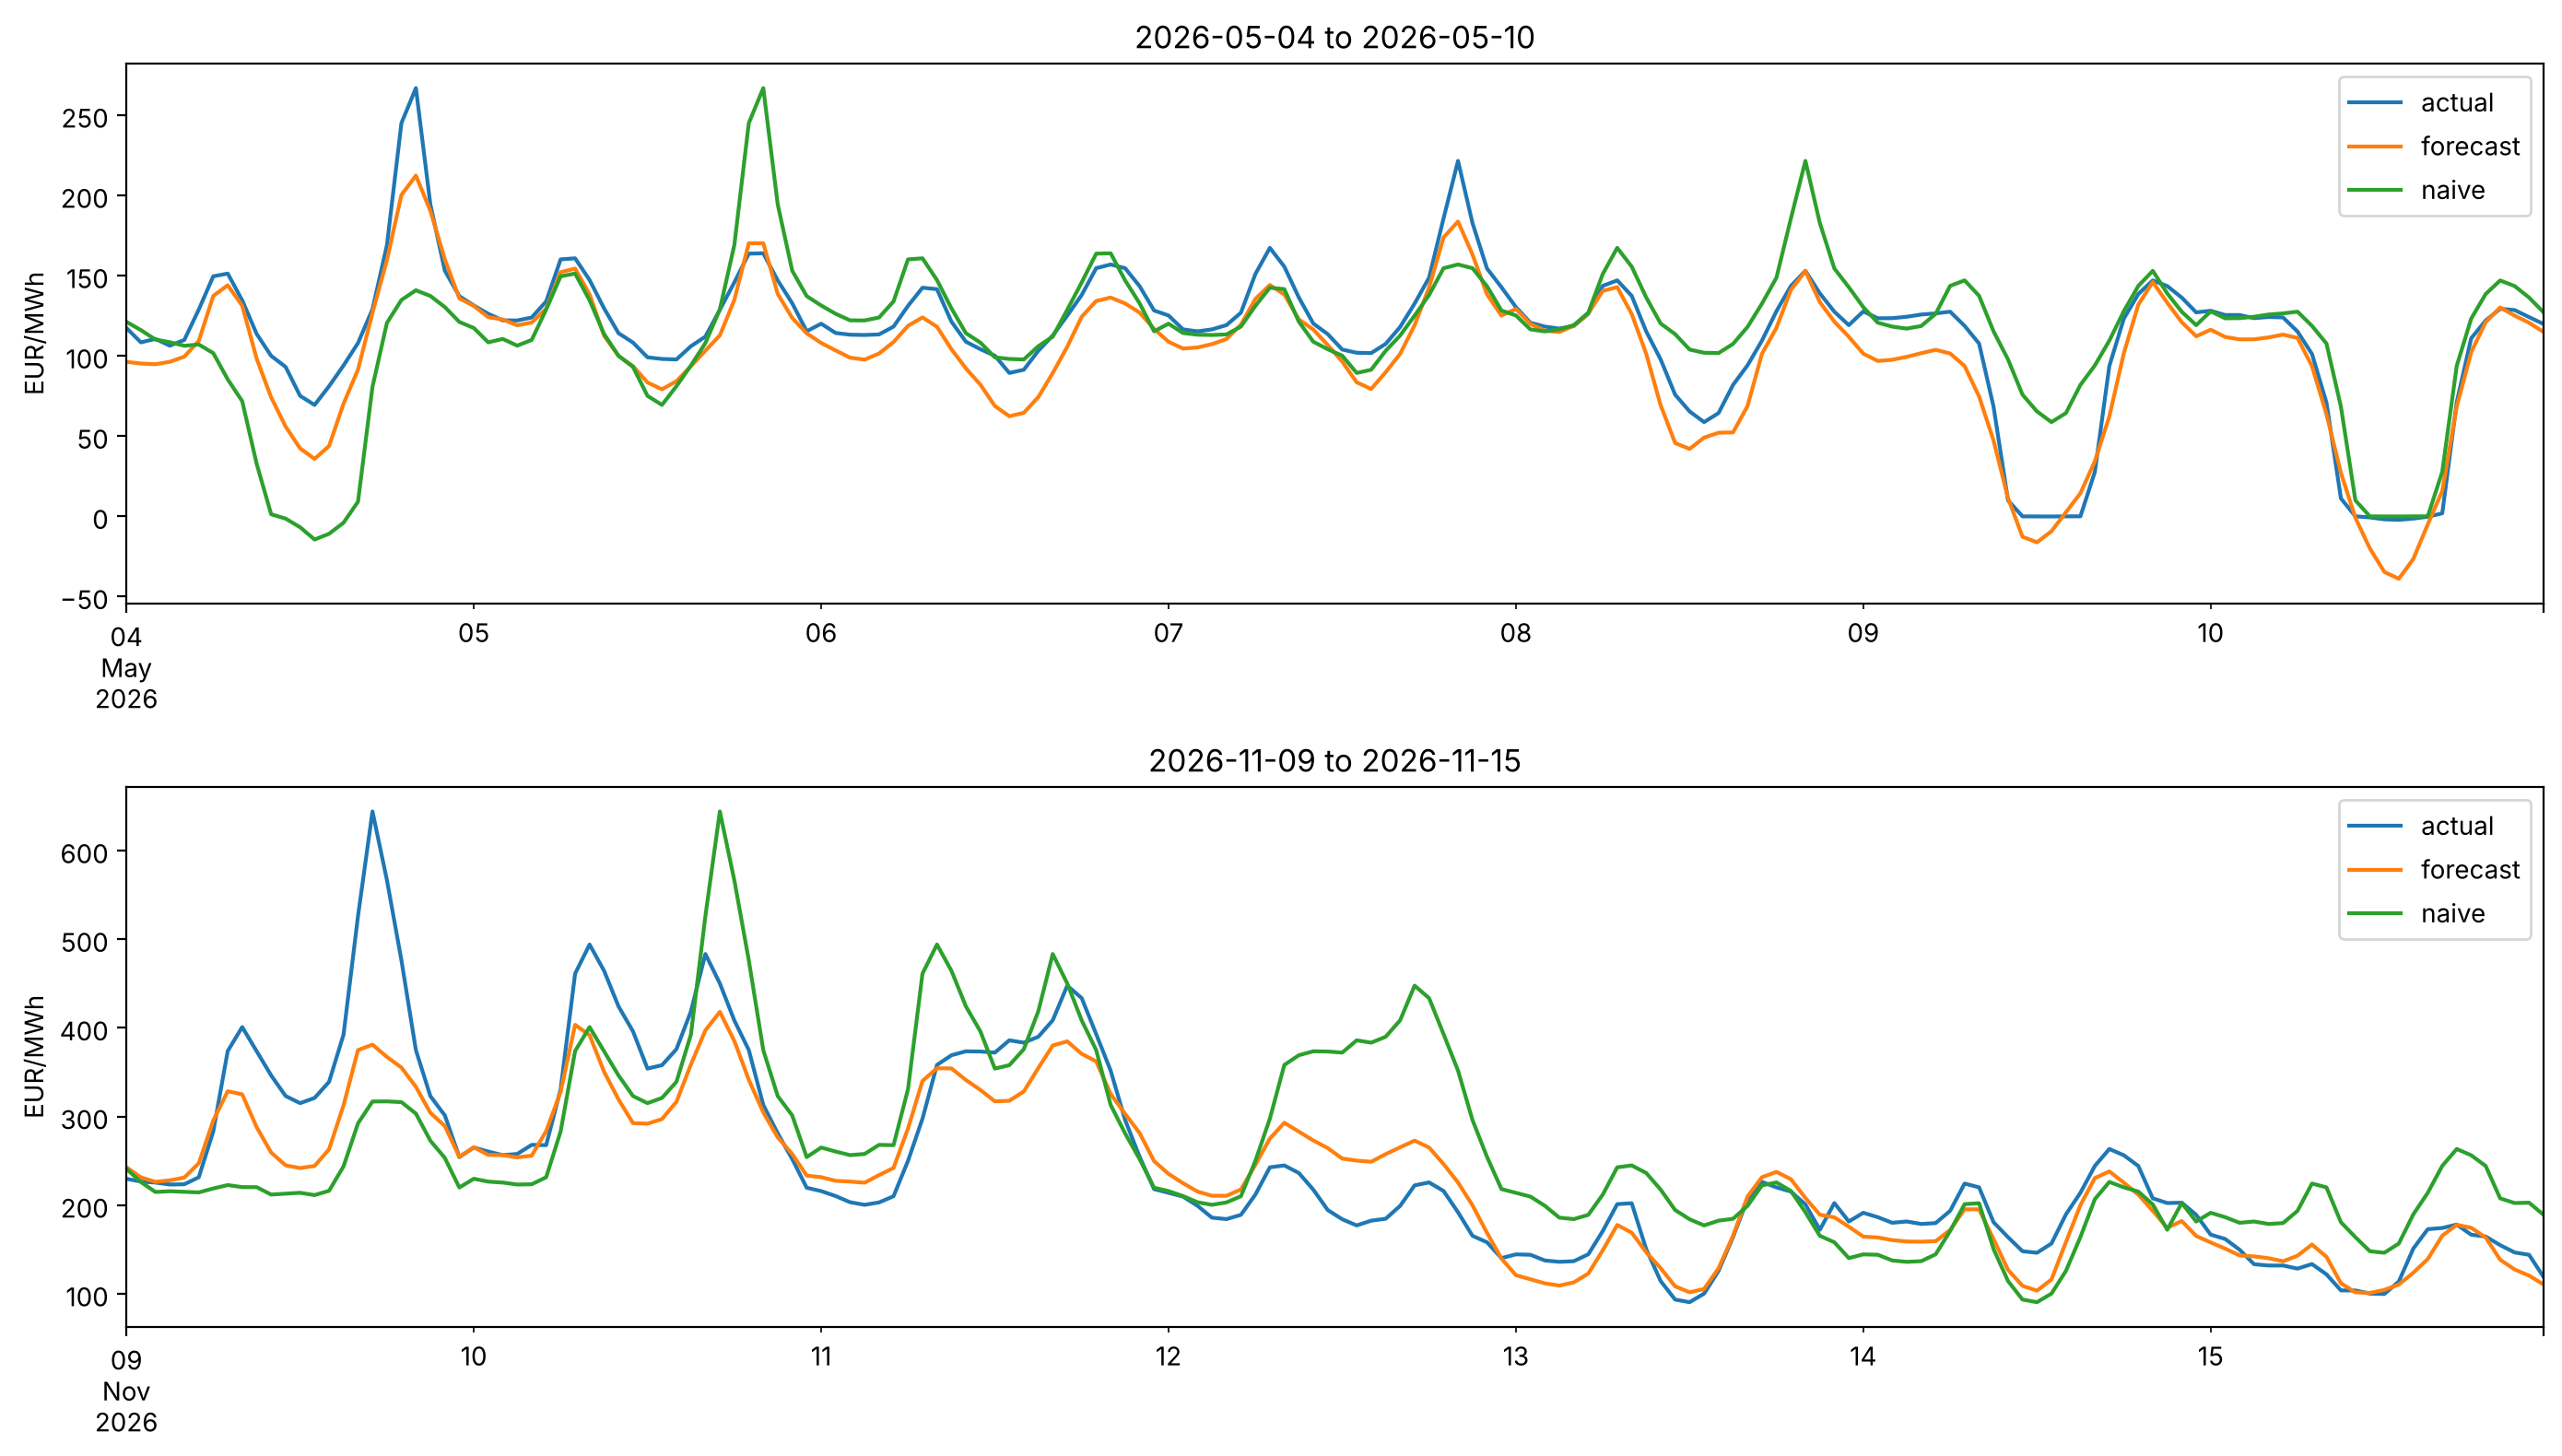

In [15]:
final_pred = test_preds[final_model_name]

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, (start, end) in zip(axes, [('2026-05-04', '2026-05-10'), ('2026-11-09', '2026-11-15')]):
    pd.DataFrame({'actual': test_y, 'forecast': final_pred, 'naive': test_X['lag24']}).loc[start:end].plot(ax=ax)
    ax.set_title(f'{start} to {end}')
    ax.set_ylabel('EUR/MWh')
plt.tight_layout()

* **May:** the model follows the daily shape well, including the midday price drops caused by solar. On the weekend of 9 and 10 May
  it predicts clearly negative prices (down to about -39 EUR/MWh), while the actual price stopped at about -2 EUR/MWh.
* **November:** the forecast reacts to the Dunkelflaute (little wind and sun), but underestimates the extreme evening spike on 9 November
  (actual 644 EUR/MWh at 17:00, forecast 381 EUR/MWh). The naive forecast is one day late for every spike.

### Where are the errors largest?

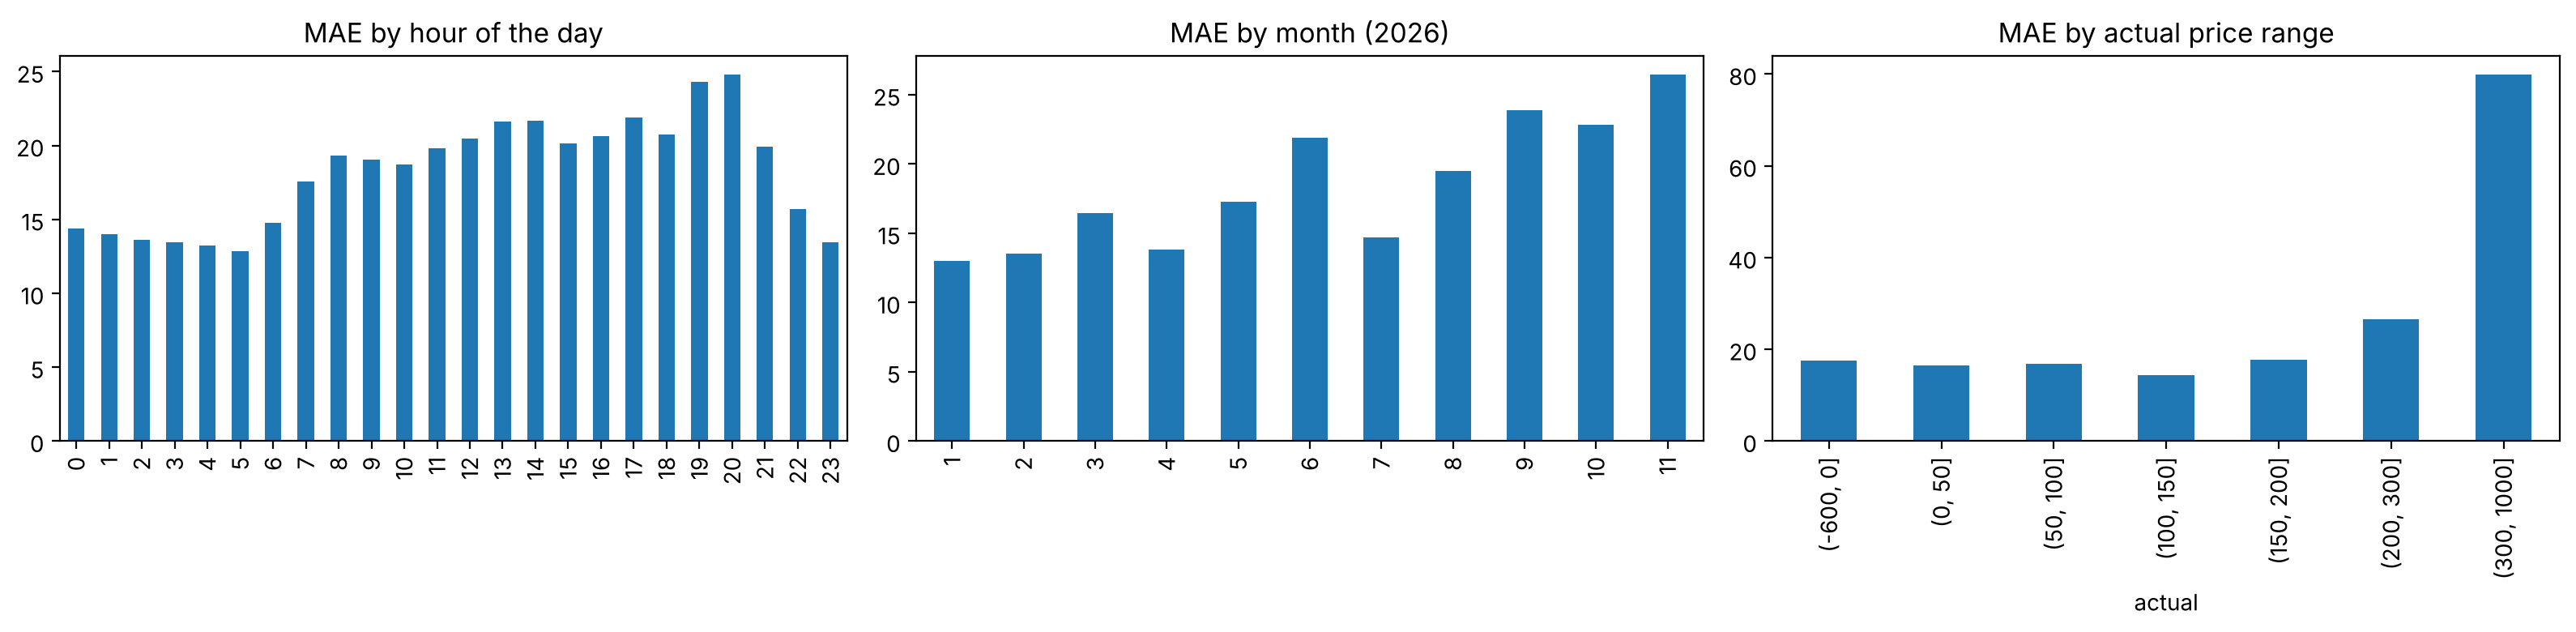

In [16]:
errors = pd.DataFrame({'actual': test_y, 'forecast': final_pred})
errors['abs_error'] = (errors['actual'] - errors['forecast']).abs()
errors['error'] = errors['actual'] - errors['forecast']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
errors.groupby(errors.index.hour)['abs_error'].mean().plot(kind='bar', ax=axes[0], title='MAE by hour of the day')
errors.groupby(errors.index.month)['abs_error'].mean().plot(kind='bar', ax=axes[1], title='MAE by month (2026)')
price_bins = pd.cut(errors['actual'], bins=[-600, 0, 50, 100, 150, 200, 300, 1000])
errors.groupby(price_bins)['abs_error'].mean().plot(kind='bar', ax=axes[2], title='MAE by actual price range')
plt.tight_layout()

In [17]:
errors.groupby(price_bins).agg(hours=('error', 'size'), mean_error=('error', 'mean'), mae=('abs_error', 'mean')).round(1)

,hours,mean_error,mae
actual,,,
"(-600, 0]",504,-3.7,17.5
"(0, 50]",693,-6.6,16.6
"(50, 100]",1451,8.0,16.8
"(100, 150]",2820,6.1,14.3
"(150, 200]",1348,9.2,17.7
"(200, 300]",745,15.5,26.5
"(300, 1000]",143,77.0,80.0


`mean_error` = actual minus forecast. The model is biased towards the average: it **overestimates** low and negative prices
and **underestimates** high prices. This is typical for models trained on data in which extreme hours are rare.

In [18]:
daily_errors = errors['abs_error'].groupby(errors.index.date).mean().sort_values(ascending=False)
worst_days = daily_errors.head(5).round(1).rename('daily MAE').to_frame()
worst_days['daily mean price'] = [test_y.loc[str(d)].mean().round(1) for d in worst_days.index]
worst_days['daily max price'] = [test_y.loc[str(d)].max().round(1) for d in worst_days.index]
worst_days

,daily MAE,daily mean price,daily max price
2026-06-24,70.5,207.8,665.8
2026-05-01,66.5,-2.1,173.3
2026-11-09,64.3,345.6,644.2
2026-06-30,62.0,187.3,504.8
2026-10-29,56.2,314.9,559.6


Four of the five worst days have very high peak prices (500-670 EUR/MWh). The other one is **1 May 2026**, a public holiday with
negative prices for most of the day. These days are driven by events that are hard to see in the forecasts of load, wind and solar alone
(plant outages, gas prices, exports to neighbouring countries).

## Which Features Matter?

We look at the random forest trained on the latest two years of data (the model that would be used for the next forecast).

**Feature importance:** how much each feature reduces the error inside the trees, summed over all splits (built into scikit-learn).

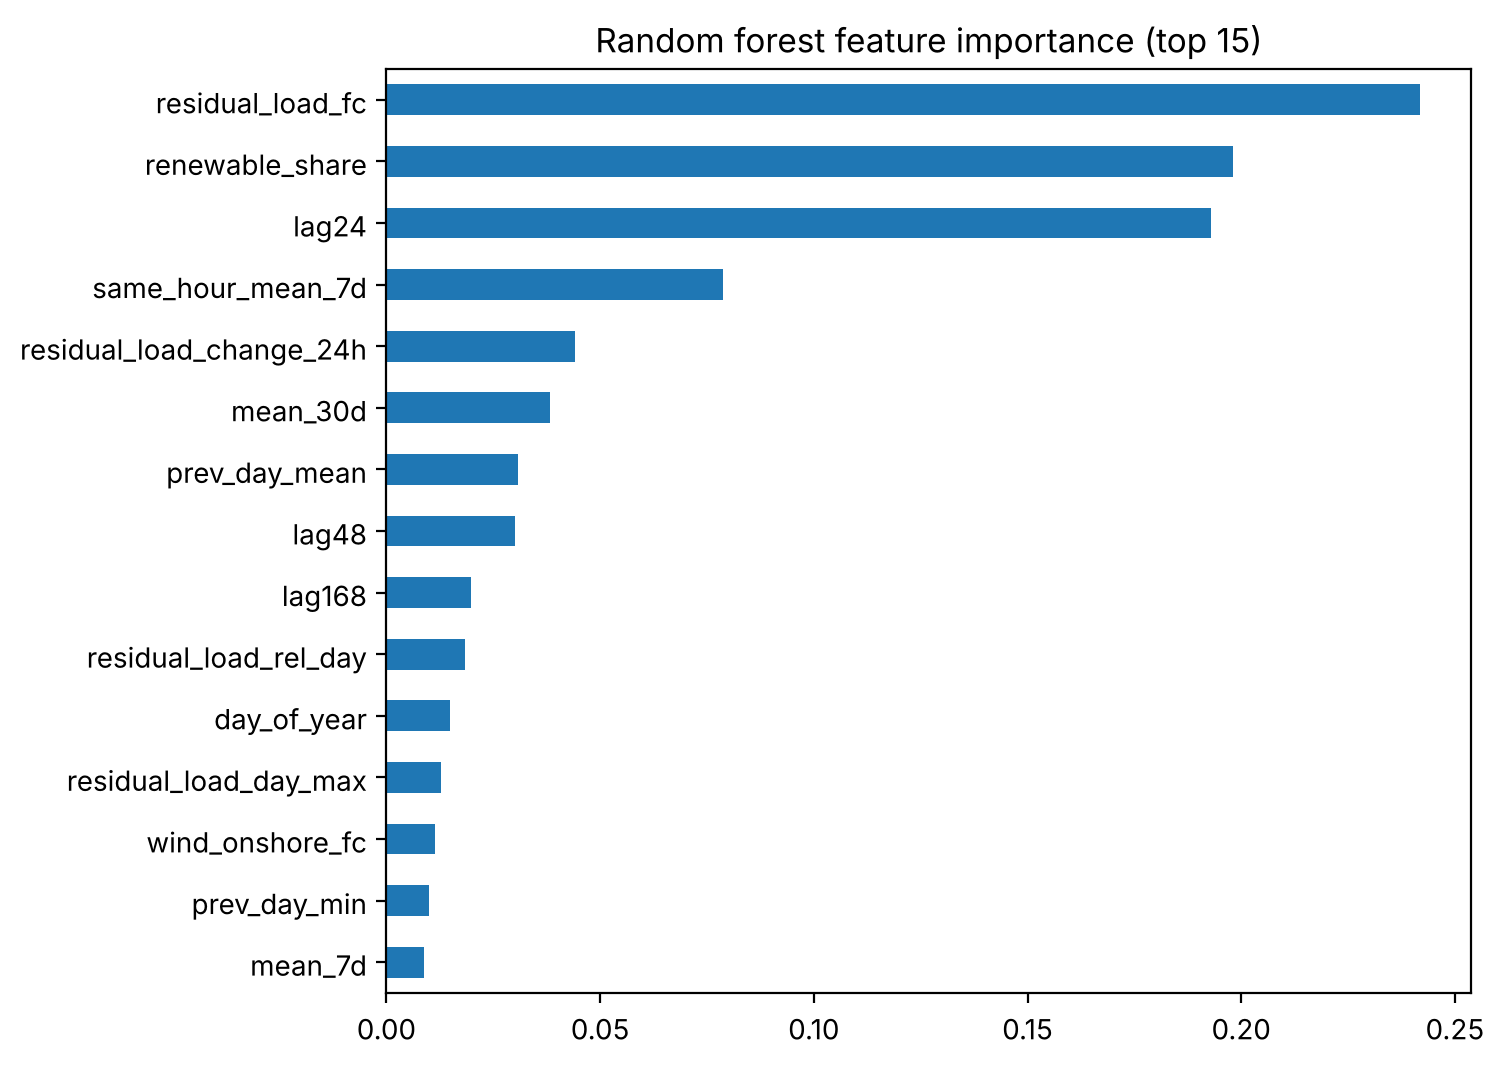

In [19]:
latest_train = features.loc['2024-11-18':'2026-11-17']
latest_rf = make_rf()
latest_rf.fit(latest_train[FEATURES], latest_train['price'])

importance = pd.Series(latest_rf.feature_importances_, index=FEATURES).sort_values()
importance.tail(15).plot(kind='barh', figsize=(7, 6), title='Random forest feature importance (top 15)');

* The **forecasted residual load** is the most important feature, followed by the **renewable share** and **yesterday's price at the same hour** (`lag24`).
  Together these three account for more than 60% of the importance.
* The price-level features (`same_hour_mean_7d`, `mean_30d`, `prev_day_mean`) come next: they tell the model how expensive the market is at the moment.
* Calendar features matter little once the residual load is known, because the residual load already contains the daily and weekly demand pattern.

Note: this importance measure is computed on the training data and tends to favour features with many different values; it is a rough guide, not an exact ranking.

**Partial dependence:** how does the forecast change when we change only the residual load and keep everything else as in the data?

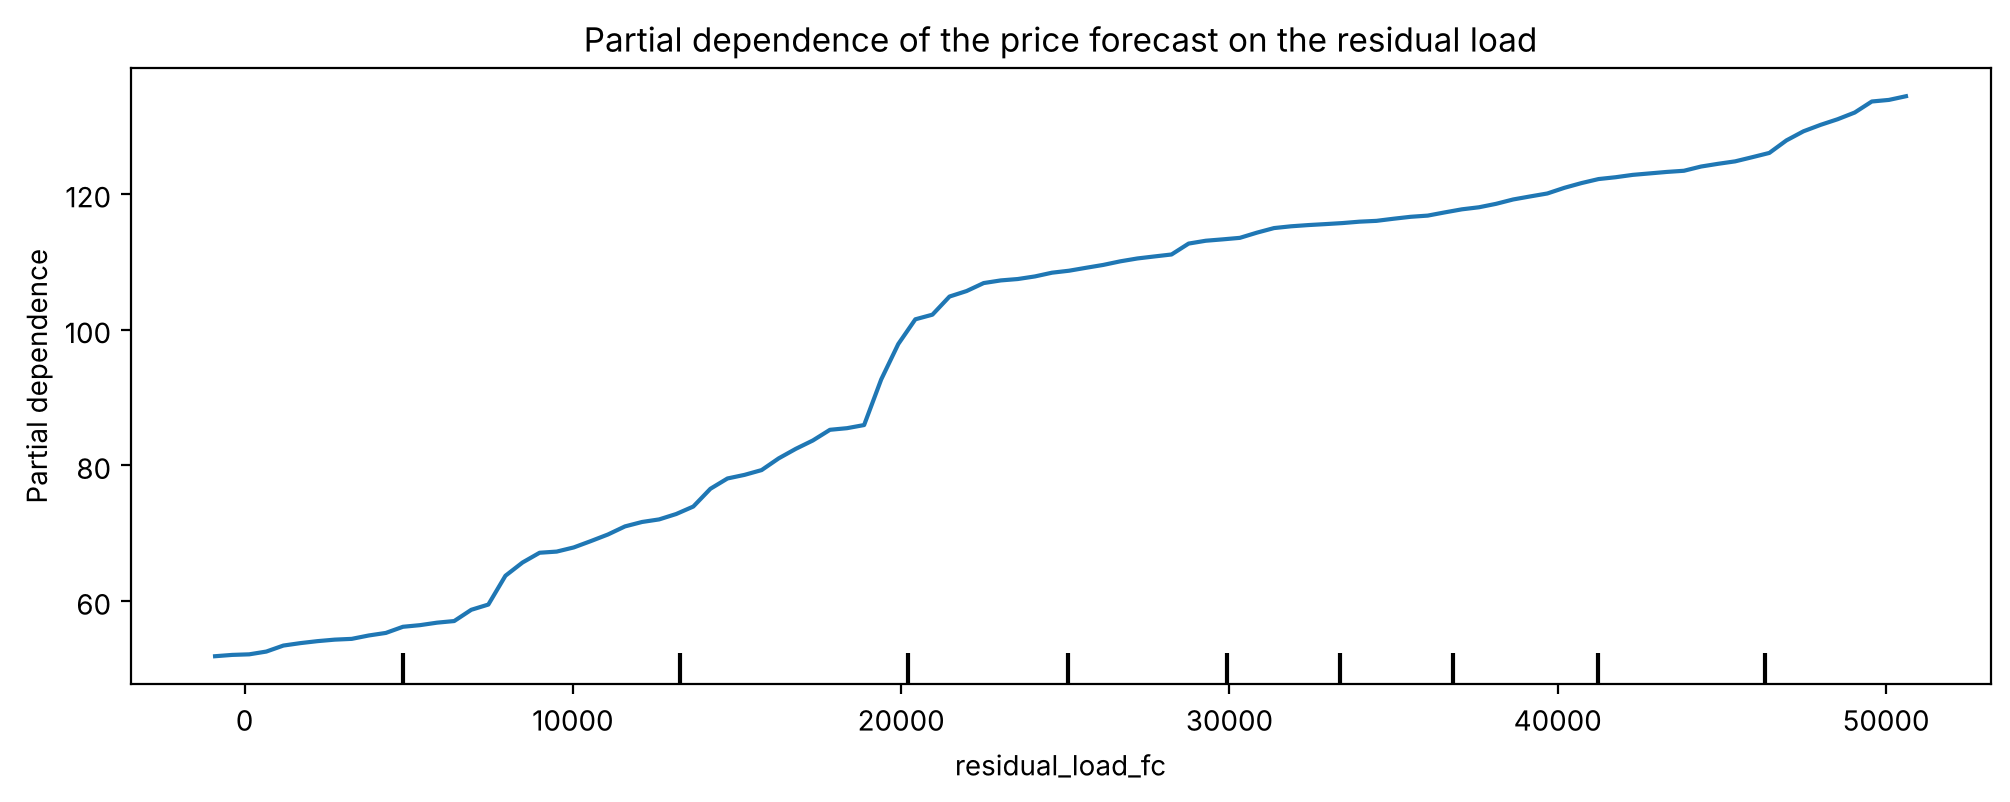

In [20]:
from sklearn.inspection import PartialDependenceDisplay

sample = test_X.sample(2000, random_state=1)
PartialDependenceDisplay.from_estimator(latest_rf, sample, ['residual_load_fc'])
plt.title('Partial dependence of the price forecast on the residual load');

The curve is the **merit order** learned from data: the forecast rises with the residual load, but not evenly.
Below about 20 GWh it falls steeply (renewables push conventional plants out of the market, prices can become negative).
Between 20 and 40 GWh it is flatter (lignite and coal plants set the price), and above about 45 GWh it rises faster again (expensive gas plants are needed).
A linear model would draw a straight line here.

## Saving the Predictions

We save all test predictions and the result tables. The dashboard (`app/dashboard.py`) and the figure script (`src/report_figures.py`) load them.

In [21]:
import os
os.makedirs('../outputs', exist_ok=True)

out = test_preds.copy()
out.insert(0, 'actual', test_y)
out.index = out.index.tz_localize(None)
out.index.name = 'time'
out.round(2).to_csv('../outputs/test_predictions_2026.csv')
test_table.round(2).to_csv('../outputs/model_comparison_test_2026.csv')
val_table.round(2).to_csv('../outputs/model_comparison_validation_2025.csv')
importance.sort_values(ascending=False).round(4).to_csv('../outputs/feature_importance_rf.csv')
print('saved')

saved


## Summary and Next Steps

**Results**

* All models clearly beat the seasonal naive forecast.
* The final model, the simple average of linear regression, random forest and MLP, was chosen on the validation year 2025. On the test year 2026 it reaches
  an MAE of 18.2 EUR/MWh, 45% better than the naive forecast, and it is more accurate than the naive forecast on 79% of the days.
* Monthly retraining on a two-year window works better than one or three years, because the market changes quickly.
* The models learn the merit order: residual load, renewable share and the recent price level drive the forecast.

**Limitations**

* Price spikes and negative prices are smoothed: the models are biased towards the average.
* The price level depends on gas and CO2 prices, which are not part of the SMARD data. Rolling features and retraining only partly
  compensate for this.
* The hyperparameters of the random forest and the MLP were set to reasonable values and not tuned systematically.

**Next steps**

* Hyperparameter tuning with `TimeSeriesSplit` (time-series cross-validation)
* Forecasting price ranges instead of single values (quantile regression)
* Forecasting directly on the 15-minute resolution of the new day-ahead market